In [ ]:

import pandas as pd
import numpy as np

DATA_PATH = "aa_dataset-tickets-multi-lang-5-2-50-version.csv"

df = pd.read_csv(DATA_PATH)

print("Original dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# Check required columns
required = ["subject", "body", "queue", "priority", "language"]
missing_columns = set(required) - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Inspect missing values
print("\nMissing values:")
print(df[required].isna().sum())

# Keep rows with valid target labels
df = df.dropna(subset=["queue", "priority"]).copy()

# Replace missing text safely
for col in ["subject", "body"]:
    df[col] = df[col].fillna("").astype(str).str.strip()

# Combine subject and body into model input
df["text"] = (
    "Subject: " + df["subject"] +
    "\nTicket: " + df["body"]
).str.strip()

# Remove tickets with no meaningful text
df = df[df["text"].str.replace(
    r"Subject:\s*|Ticket:\s*", "", regex=True
).str.strip().ne("")].copy()

# Normalize target labels
df["queue"] = df["queue"].astype(str).str.strip()
df["priority"] = df["priority"].astype(str).str.strip().str.lower()

print("\nCleaned dataset shape:", df.shape)

print("\nQueue distribution:")
print(df["queue"].value_counts())

print("\nPriority distribution:")
print(df["priority"].value_counts())

print("\nLanguage distribution:")
print(df["language"].value_counts(dropna=False))

print("\nSample:")
display(df[["text", "queue", "priority"]].head(5))


Original dataset shape: (28587, 16)

Columns:
['subject', 'body', 'answer', 'type', 'queue', 'priority', 'language', 'version', 'tag_1', 'tag_2', 'tag_3', 'tag_4', 'tag_5', 'tag_6', 'tag_7', 'tag_8']

Missing values:
subject     3838
body           0
queue          0
priority       0
language       0
dtype: int64

Cleaned dataset shape: (28587, 17)

Queue distribution:
queue
Technical Support                  8362
Product Support                    5252
Customer Service                   4268
IT Support                         3433
Billing and Payments               2788
Returns and Exchanges              1437
Service Outages and Maintenance    1148
Sales and Pre-Sales                 918
Human Resources                     576
General Inquiry                     405
Name: count, dtype: int64

Priority distribution:
priority
medium    11515
high      11178
low        5894
Name: count, dtype: int64

Language distribution:
language
en    16338
de    12249
Name: count, dtype: int64

Sampl

,text,queue,priority
0,Subject: Wesentlicher Sicherheitsvorfall\nTick...,Technical Support,high
1,Subject: Account Disruption\nTicket: Dear Cust...,Technical Support,high
2,Subject: Query About Smart Home System Integra...,Returns and Exchanges,medium
3,Subject: Inquiry Regarding Invoice Details\nTi...,Billing and Payments,low
4,Subject: Question About Marketing Agency Softw...,Sales and Pre-Sales,medium


In [ ]:
import torch
import transformers
import importlib.util

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())

# Check TPU backends
print(
    "PyTorch/XLA installed:",
    importlib.util.find_spec("torch_xla") is not None
)
print(
    "TorchTPU installed:",
    importlib.util.find_spec("torchtpu") is not None
)

# Check for NVIDIA GPU
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Check for PyTorch/XLA TPU
if importlib.util.find_spec("torch_xla") is not None:
    try:
        import torch_xla
        import torch_xla.core.xla_model as xm
        print("XLA device:", xm.xla_device())
    except Exception as e:
        print("XLA device check failed:", repr(e))

PyTorch: 2.11.0+cu130
Transformers: 5.22.0
CUDA available: True
PyTorch/XLA installed: False
TorchTPU installed: False
GPU: Tesla T4


PyTorch: 2.11.0+cu130
Transformers: 5.22.0
CUDA available: True
GPU: Tesla T4

Initial cleaned dataset: 28587
Conflicting text examples: 0
Duplicate rows removed: 0
Final dataset size: 28587

Number of classes: 10

Queue distribution:
queue
Technical Support                  8362
Product Support                    5252
Customer Service                   4268
IT Support                         3433
Billing and Payments               2788
Returns and Exchanges              1437
Service Outages and Maintenance    1148
Sales and Pre-Sales                 918
Human Resources                     576
General Inquiry                     405
Name: count, dtype: int64

Dataset split:
Training: 22869
Validation: 2859
Test: 2859


config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

Map:   0%|          | 0/22869 [00:00<?, ? examples/s]

... (20 outputs left out)

,precision,recall,f1-score,support
Billing and Payments,0.7770,0.7742,0.7756,279.0000
Customer Service,0.4005,0.3630,0.3808,427.0000
General Inquiry,0.1875,0.2250,0.2045,40.0000
Human Resources,0.4314,0.3860,0.4074,57.0000
IT Support,0.4335,0.4738,0.4528,344.0000
Product Support,0.3690,0.3543,0.3615,525.0000
Returns and Exchanges,0.3472,0.3472,0.3472,144.0000
Sales and Pre-Sales,0.4483,0.4239,0.4358,92.0000
Service Outages and Maintenance,0.7213,0.7652,0.7426,115.0000
Technical Support,0.5348,0.5514,0.5430,836.0000



Confusion matrix:


,Billing and Payments,Customer Service,General Inquiry,Human Resources,IT Support,Product Support,Returns and Exchanges,Sales and Pre-Sales,Service Outages and Maintenance,Technical Support
Billing and Payments,216,24,0,2,4,5,5,8,1,14
Customer Service,13,155,7,6,25,99,25,16,2,79
General Inquiry,0,9,9,0,6,7,2,1,0,6
Human Resources,3,4,1,22,2,14,2,2,1,6
IT Support,7,17,5,5,163,28,7,2,9,101
Product Support,11,71,12,4,32,186,28,8,6,167
Returns and Exchanges,5,29,2,1,7,30,50,4,1,15
Sales and Pre-Sales,1,20,1,2,8,10,3,39,2,6
Service Outages and Maintenance,0,1,1,1,6,10,1,0,88,7
Technical Support,22,57,10,8,123,115,21,7,12,461


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

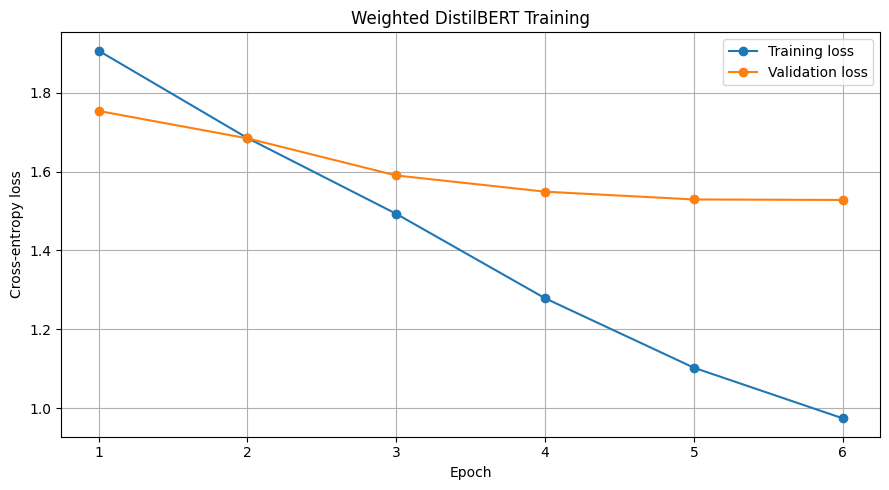


Final experiment results:


,model,test_loss,accuracy,macro_f1,weighted_f1
0,weighted_distilbert,1.52198,0.485834,0.465125,0.484572



All artifacts saved to: /content/ticket-queue-experiments/weighted_distilbert
Classification report saved.
Confusion matrix saved.
Training history saved.
Loss curve saved.
Model and tokenizer saved.


In [ ]:

import os
import json
import inspect
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import transformers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    EarlyStoppingCallback,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    set_seed,
)

from torch.nn import CrossEntropyLoss


# ============================================================
# 1. CONFIGURATION
# ============================================================

SEED = 42
set_seed(SEED)

MODEL_NAME = "distilbert/distilbert-base-multilingual-cased"

MAX_LENGTH = 195

OUTPUT_BASE = "/content/ticket-queue-experiments"

# Separate experiment: do not overwrite the standard model.
OUTPUT_DIR = os.path.join(
    OUTPUT_BASE,
    "weighted_distilbert"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


# ============================================================
# 2. DATA VALIDATION AND CLEANING
# ============================================================

assert "text" in df.columns, "Missing text column."
assert "queue" in df.columns, "Missing queue column."

data = df[["text", "queue"]].copy()

data["text"] = (
    data["text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

data["queue"] = (
    data["queue"]
    .fillna("")
    .astype(str)
    .str.strip()
)

data = data[
    (data["text"] != "") &
    (data["queue"] != "")
].reset_index(drop=True)

print("\nInitial cleaned dataset:", len(data))


# Identify identical text assigned to multiple queues.
conflicting_texts = (
    data.groupby("text")["queue"]
    .nunique()
)

conflicting_texts = conflicting_texts[
    conflicting_texts > 1
].index

print(
    "Conflicting text examples:",
    len(conflicting_texts)
)

# Remove ambiguous examples from this experiment.
if len(conflicting_texts) > 0:
    data = data[
        ~data["text"].isin(conflicting_texts)
    ].reset_index(drop=True)


# Remove exact duplicate text/queue pairs.
before_dedup = len(data)

data = data.drop_duplicates(
    subset=["text", "queue"]
).reset_index(drop=True)

print("Duplicate rows removed:", before_dedup - len(data))
print("Final dataset size:", len(data))


# ============================================================
# 3. LABEL ENCODING
# ============================================================

encoder = LabelEncoder()

data["label"] = encoder.fit_transform(data["queue"])

num_labels = len(encoder.classes_)

print("\nNumber of classes:", num_labels)

print("\nQueue distribution:")
print(data["queue"].value_counts())

class_counts = data["label"].value_counts()

if class_counts.min() < 3:
    raise ValueError(
        "Insufficient examples for stratified splitting."
    )


# ============================================================
# 4. TRAIN / VALIDATION / TEST SPLIT
# ============================================================

train_df, temp_df = train_test_split(
    data,
    test_size=0.20,
    random_state=SEED,
    stratify=data["label"],
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"],
)

print("\nDataset split:")
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


# ============================================================
# 5. TOKENIZATION
# ============================================================

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def prepare_dataset(frame):

    ds = Dataset.from_pandas(
        frame[["text", "label"]].reset_index(drop=True)
    )

    ds = ds.map(
        lambda batch: tokenizer(
            batch["text"],
            truncation=True,
            max_length=MAX_LENGTH,
        ),
        batched=True,
    )

    ds = ds.remove_columns(["text"])
    ds = ds.rename_column("label", "labels")

    return ds


train_ds = prepare_dataset(train_df)
val_ds = prepare_dataset(val_df)
test_ds = prepare_dataset(test_df)

collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)


# ============================================================
# 6. LABEL MAPPING
# ============================================================

id2label = {
    idx: label
    for idx, label in enumerate(encoder.classes_)
}

label2id = {
    label: idx
    for idx, label in enumerate(encoder.classes_)
}


# ============================================================
# 7. EVALUATION METRICS
# ============================================================

def compute_metrics(eval_pred):

    logits = eval_pred.predictions

    if isinstance(logits, tuple):
        logits = logits[0]

    labels = eval_pred.label_ids

    predictions = np.argmax(
        logits,
        axis=-1
    )

    return {
        "accuracy": accuracy_score(
            labels,
            predictions
        ),

        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro",
            zero_division=0,
        ),

        "weighted_f1": f1_score(
            labels,
            predictions,
            average="weighted",
            zero_division=0,
        ),
    }


# ============================================================
# 8. CLASS WEIGHT CALCULATION
# ============================================================

# Calculate weights using TRAINING DATA ONLY.

classes = np.arange(num_labels)

class_weights_np = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"].values
)

# Square-root weights are less aggressive than
# full inverse-frequency weights.

class_weights_np = np.sqrt(class_weights_np)

# Normalize average weight to 1.

class_weights_np = (
    class_weights_np / class_weights_np.mean()
)

class_weights = torch.tensor(
    class_weights_np,
    dtype=torch.float32
)

print("\nClass weights:")

for label, weight in zip(
    encoder.classes_,
    class_weights_np
):
    print(f"{label}: {weight:.4f}")


# Save class weights.

with open(
    os.path.join(OUTPUT_DIR, "class_weights.json"),
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        {
            label: float(weight)
            for label, weight in zip(
                encoder.classes_,
                class_weights_np
            )
        },
        f,
        indent=4
    )


# ============================================================
# 9. VERSION-COMPATIBLE TRAINING ARGUMENTS
# ============================================================

def make_args(output_dir):

    params = inspect.signature(
        TrainingArguments.__init__
    ).parameters

    args = {
        "output_dir": output_dir,
        "learning_rate": 2e-5,
        "per_device_train_batch_size": 16,
        "per_device_eval_batch_size": 32,
        "gradient_accumulation_steps": 1,
        "num_train_epochs": 6,
        "weight_decay": 0.01,
        "load_best_model_at_end": True,
        "metric_for_best_model": "eval_macro_f1",
        "greater_is_better": True,
        "fp16": torch.cuda.is_available(),
        "report_to": "none",
        "save_total_limit": 2,
        "seed": SEED,
    }

    if "eval_strategy" in params:
        args["eval_strategy"] = "epoch"

    elif "evaluation_strategy" in params:
        args["evaluation_strategy"] = "epoch"

    else:
        raise RuntimeError(
            "No supported evaluation strategy found."
        )

    optional_args = {
        "save_strategy": "epoch",
        "logging_strategy": "epoch",
        "warmup_ratio": 0.1,
        "dataloader_num_workers": 0,
        "use_cpu": not torch.cuda.is_available(),
    }

    for key, value in optional_args.items():
        if key in params:
            args[key] = value

    # Remove unsupported arguments.
    args = {
        key: value
        for key, value in args.items()
        if key in params
    }

    return TrainingArguments(**args)


training_args = make_args(OUTPUT_DIR)


# ============================================================
# 10. WEIGHTED TRAINER
# ============================================================

class WeightedTrainer(Trainer):

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None,
    ):

        labels = inputs["labels"]

        model_inputs = {
            key: value
            for key, value in inputs.items()
            if key != "labels"
        }

        outputs = model(**model_inputs)

        weights = class_weights.to(
            outputs.logits.device
        )

        loss_function = CrossEntropyLoss(
            weight=weights
        )

        loss = loss_function(
            outputs.logits,
            labels
        )

        return (
            (loss, outputs)
            if return_outputs
            else loss
        )


# ============================================================
# 11. MODEL INITIALIZATION
# ============================================================

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=collator,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=2
        )
    ],
)

print("\nExperiment: weighted_distilbert")
print("Class weighting: True")
print("Weighting method: Square-root inverse frequency")
print("Checkpoint selection: Validation macro F1")


# ============================================================
# 12. TRAINING
# ============================================================

trainer.train()

print(
    "\nBest checkpoint:",
    trainer.state.best_model_checkpoint
)

print(
    "Best validation macro F1:",
    trainer.state.best_metric
)


# ============================================================
# 13. FINAL TEST EVALUATION
# ============================================================

print("\nFinal test evaluation")

test_results = trainer.evaluate(
    eval_dataset=test_ds,
    metric_key_prefix="test",
)

for metric, value in test_results.items():
    print(f"{metric}: {value}")


# ============================================================
# 14. CLASSIFICATION REPORT
# ============================================================

predictions_output = trainer.predict(
    test_ds,
    metric_key_prefix="test",
)

logits = predictions_output.predictions

if isinstance(logits, tuple):
    logits = logits[0]

y_pred = np.argmax(
    logits,
    axis=-1
)

y_true = predictions_output.label_ids

report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(num_labels),
    target_names=encoder.classes_,
    zero_division=0,
    output_dict=True,
)

report_df = pd.DataFrame(report).T

print("\nClassification report:")
display(report_df.round(4))


# Save classification report.

report_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "classification_report.csv"
    )
)


# ============================================================
# 15. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(num_labels),
)

cm_df = pd.DataFrame(
    cm,
    index=encoder.classes_,
    columns=encoder.classes_,
)

print("\nConfusion matrix:")
display(cm_df)

cm_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "confusion_matrix.csv"
    )
)


# ============================================================
# 16. SAVE MODEL AND TOKENIZER
# ============================================================

trainer.save_model(OUTPUT_DIR)

tokenizer.save_pretrained(OUTPUT_DIR)

with open(
    os.path.join(
        OUTPUT_DIR,
        "label_classes.json"
    ),
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        encoder.classes_.tolist(),
        f,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# 17. SAVE EXPERIMENT METRICS
# ============================================================

final_metrics = {
    key: float(value)
    for key, value in test_results.items()
    if isinstance(value, (int, float, np.integer, np.floating))
}

with open(
    os.path.join(
        OUTPUT_DIR,
        "test_metrics.json"
    ),
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        final_metrics,
        f,
        indent=4
    )


# ============================================================
# 18. SAVE TRAINING HISTORY
# ============================================================

history = pd.DataFrame(
    trainer.state.log_history
)

history_path = os.path.join(
    OUTPUT_DIR,
    "training_history.csv"
)

history.to_csv(
    history_path,
    index=False
)


# ============================================================
# 19. TRAINING LOSS VISUALIZATION
# ============================================================

fig, ax = plt.subplots(figsize=(9, 5))

train_history = history.dropna(
    subset=["loss"]
)

val_history = history.dropna(
    subset=["eval_loss"]
)

if not train_history.empty:

    ax.plot(
        train_history["epoch"],
        train_history["loss"],
        marker="o",
        label="Training loss",
    )

if not val_history.empty:

    ax.plot(
        val_history["epoch"],
        val_history["eval_loss"],
        marker="o",
        label="Validation loss",
    )

ax.set_title(
    "Weighted DistilBERT Training"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy loss")

ax.legend()
ax.grid(True)

plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "loss_curve.png"),
    dpi=150
)
plt.show()


# ============================================================
# 20. FINAL SUMMARY
# ============================================================

comparison = pd.DataFrame([
    {
        "model": "weighted_distilbert",
        "test_loss": test_results.get("test_loss"),
        "accuracy": test_results.get("test_accuracy"),
        "macro_f1": test_results.get("test_macro_f1"),
        "weighted_f1": test_results.get("test_weighted_f1"),
    }
])

print("\nFinal experiment results:")
display(comparison)

print("\nAll artifacts saved to:", OUTPUT_DIR)
print("Classification report saved.")
print("Confusion matrix saved.")
print("Training history saved.")
print("Loss curve saved.")
print("Model and tokenizer saved.")


In [ ]:
from google.colab import drive
from pathlib import Path
import shutil

drive.mount("/content/drive")

SOURCE = Path(
    "/content/ticket-queue-experiments/weighted_distilbert"
)

DESTINATION = Path(
    "/content/drive/MyDrive/MLOps_Project/weighted_distilbert"
)

DESTINATION.parent.mkdir(parents=True, exist_ok=True)

if not SOURCE.exists():
    raise FileNotFoundError(SOURCE)

if DESTINATION.exists():
    print("Destination already exists.")
else:
    shutil.copytree(SOURCE, DESTINATION)

print("Model saved to:", DESTINATION)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved to: /content/drive/MyDrive/MLOps_Project/weighted_distilbert


In [ ]:
from pathlib import Path

MODEL_PATH = Path(
    "/content/drive/MyDrive/MLOps_Project/weighted_distilbert"
)

required_files = [
    "config.json",
    "model.safetensors",
    "tokenizer.json",
    "label_classes.json",
]

for filename in required_files:
    path = MODEL_PATH / filename
    print(filename, ":", path.exists())

config.json : True
model.safetensors : True
tokenizer.json : True
label_classes.json : True
